# S³ semantic-axis smoke test

This exploratory test fits Turftopic S³ to the existing semantic passages using the saved BGE-M3 vectors. Passage embeddings are loaded from disk and passed through `embeddings=`; they are not recomputed. The matching local BGE model is used only for vocabulary-term embeddings.

This fit uses 15 components and seed 42. Scores are signed ICA coordinates, not calibrated probabilities or BERTopic topics. Review the displayed positive/negative evidence before interpreting an axis. Original BERTopic assignments are not changed.

Run from the repository root with `uv run --group topic-analysis jupyter lab`.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer
from turftopic import SemanticSignalSeparation

project_root = Path.cwd().resolve()
if not (project_root / 'data/topic-analysis').exists():
    project_root = project_root.parent
if not (project_root / 'data/topic-analysis').exists():
    raise FileNotFoundError('Could not locate data/topic-analysis from the notebook working directory')
results = project_root / 'data/topic-analysis/results'
dataset_path = results / 'segment-dataset/all-segments.parquet'
embedding_path = results / 'jev-semantic-all/bubble-maps/segment-embeddings.npy'
embedding_manifest_path = results / 'jev-semantic-all/bubble-maps/embedding-manifest.json'
model_manifest_path = results / 'segment-dataset/manifest.json'
MODEL_ID = 'BAAI/bge-m3'
MODEL_REVISION = '5617a9f61b028005a4858fdac845db406aefb181'
N_COMPONENTS, RANDOM_STATE = 15, 42
print(f'Project: {project_root}')
print(f'Saved vectors: {embedding_path}')

Project: C:\Users\risto\projects\arvamusfestivali_salvestused
Saved vectors: C:\Users\risto\projects\arvamusfestivali_salvestused\data\topic-analysis\results\jev-semantic-all\bubble-maps\segment-embeddings.npy


C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\_snmf.py:20: UserWarning: JAX not found, continuing with NumPy implementation.
  warnings.warn("JAX not found, continuing with NumPy implementation.")


In [2]:
wanted = ['segment_key', 'segmentation', 'passage_id', 'episode_id', 'title', 'start_seconds', 'end_seconds', 'text', 'audio_url', 'topic_id', 'membership_strength']
available = set(pd.read_parquet(dataset_path).columns)
all_passages = pd.read_parquet(dataset_path, columns=[c for c in wanted if c in available])
passages = all_passages.loc[all_passages.segmentation == 'semantic'].reset_index(drop=True)
embedding_manifest = json.loads(embedding_manifest_path.read_text(encoding='utf-8'))
model_info = json.loads(model_manifest_path.read_text(encoding='utf-8'))['models']['semantic']
embeddings = np.load(embedding_path, allow_pickle=False)
assert model_info['embedding_model_id'] == MODEL_ID
assert model_info['embedding_revision'] == MODEL_REVISION
assert int(model_info['embedding_dimension']) == 1024
assert passages.segment_key.tolist() == embedding_manifest['segment_keys'], 'Passage/vector order mismatch'
assert embeddings.shape == (len(passages), 1024), embeddings.shape
assert embeddings.dtype == np.float32 and np.isfinite(embeddings).all()
assert np.allclose(np.linalg.norm(embeddings, axis=1), 1.0, atol=1e-4), 'Vectors are not L2-normalized'
print(f'Validated {len(passages):,} passages × {embeddings.shape[1]} dimensions; float32, finite, L2-normalized.')
print(f"Model: {model_info['embedding_model_id']} @ {model_info['embedding_revision']}")
print(f"Original BERTopic outliers (topic -1): {(passages.topic_id == -1).sum():,}")

Validated 4,132 passages × 1024 dimensions; float32, finite, L2-normalized.
Model: BAAI/bge-m3 @ 5617a9f61b028005a4858fdac845db406aefb181
Original BERTopic outliers (topic -1): 827


## Fit on the precomputed vectors

The encoder is loaded from local cache only. If that exact revision is not cached, the cell fails instead of downloading or substituting another model. Turftopic receives the corpus matrix directly via `embeddings=embeddings`.

In [3]:
encoder = SentenceTransformer(MODEL_ID, revision=MODEL_REVISION, local_files_only=True)
s3 = SemanticSignalSeparation(n_components=N_COMPONENTS, encoder=encoder, vectorizer=CountVectorizer(max_features=500), random_state=RANDOM_STATE)
scores = s3.fit_transform(passages.text.tolist(), embeddings=embeddings)
assert scores.shape == (len(passages), N_COMPONENTS), scores.shape
assert np.isfinite(scores).all(), 'S³ scores contain non-finite values'
score_columns = [f's3_component_{i}' for i in range(N_COMPONENTS)]
scored_passages = passages.copy()
for i, column in enumerate(score_columns):
    scored_passages[column] = scores[:, i]
print(f'S³ fit passed: {len(passages):,} passages, {N_COMPONENTS} components, seed {RANDOM_STATE}.')
print('Passage vectors came from disk; no passage re-embedding was run.')

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Output()

C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\sklearn\decompositio
n\_fastica.py:132: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum 
number of iterations.
  warnings.warn(

[18:24:26] Decomposition done.                                                                        ]8;id=672537;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=191757;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#156\156]8;;\

[18:24:29] Term extraction done.                                                                      ]8;id=968920;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=49391;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#159\159]8;;\

[18:24:46] Vocabulary encoded.                                                                        ]8;id=263806;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=538764;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#169\169]8;;\

           Model fitting done.                                                                        ]8;id=610099;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=803064;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#189\189]8;;\

S³ fit passed: 4,132 passages, 15 components, seed 42.
Passage vectors came from disk; no passage re-embedding was run.


## S³ component summary and naming evidence

S³ returns continuous bipolar axes, not discrete topic assignments. The dominant-axis count below is only an exploratory tally: each passage is counted under the component with its largest absolute standardized score. It is not a cluster count or a calibrated classification. For naming, review Turftopic's high/low term lists alongside the positive/negative extreme passages below, then enter a human-reviewed bipolar label; no labels are generated automatically.

In [4]:
score_frame = pd.DataFrame(scores, columns=score_columns)
score_std = score_frame.std(ddof=0).replace(0, 1)
score_z = (score_frame - score_frame.mean()) / score_std
dominant_component_index = np.abs(score_z.to_numpy()).argmax(axis=1)
dominant_counts = pd.Series(dominant_component_index).value_counts().reindex(range(N_COMPONENTS), fill_value=0)
positive_terms = s3.get_top_words(top_k=12, positive=True)
negative_terms = s3.get_top_words(top_k=12, positive=False)

component_stats = pd.DataFrame({
    'component_id': range(N_COMPONENTS),
    'passage_count': len(score_frame),
    'score_nan_count': score_frame.isna().sum().to_numpy(),
    'positive_score_count': score_frame.gt(0).sum().to_numpy(),
    'negative_score_count': score_frame.lt(0).sum().to_numpy(),
    'mean_score': score_frame.mean().to_numpy(),
    'score_std': score_frame.std(ddof=0).to_numpy(),
    'min_score': score_frame.min().to_numpy(),
    'max_score': score_frame.max().to_numpy(),
    'dominant_axis_passages_exploratory': dominant_counts.to_numpy(),
})
print(f'S³ passages scored: {len(score_frame):,}; missing passage texts: {passages.text.isna().sum():,}; blank passage texts: {(passages.text.notna() & passages.text.astype("string").str.strip().eq("")).sum():,}')
print('Continuous score distribution and exploratory dominant-axis counts (not topic membership)')
display(component_stats)

axis_review = pd.DataFrame({
    'component_id': range(N_COMPONENTS),
    'positive_end_terms': [', '.join(words) for words in positive_terms],
    'negative_end_terms': [', '.join(words) for words in negative_terms],
    'reviewed_bipolar_label': ['' for _ in range(N_COMPONENTS)],
    'review_notes': ['' for _ in range(N_COMPONENTS)],
})
print('Naming evidence: use both ends of each axis and verify them against the extreme passages in the next cell.')
display(axis_review)
assert int(component_stats.passage_count.iloc[0]) == len(passages)
assert int(component_stats.score_nan_count.sum()) == int(score_frame.isna().sum().sum())
assert int(component_stats.dominant_axis_passages_exploratory.sum()) == len(passages)
print(f"S3_COMPONENT_STATS_OK passages={len(passages):,}; components={N_COMPONENTS}; missing_scores={int(score_frame.isna().sum().sum())}")

S³ passages scored: 4,132; missing passage texts: 0; blank passage texts: 0
Continuous score distribution and exploratory dominant-axis counts (not topic membership)


,component_id,passage_count,score_nan_count,positive_score_count,negative_score_count,mean_score,score_std,min_score,max_score,dominant_axis_passages_exploratory
0,0,4132,0,1786,2346,-3.988260e-07,1.0,-2.736689,4.687684,259
1,1,4132,0,2114,2018,2.067987e-07,1.0,-3.776582,3.560821,287
2,2,4132,0,1779,2353,-2.141844e-07,1.0,-2.948502,4.431993,290
3,3,4132,0,2006,2126,-1.384813e-07,1.0,-3.600139,3.783680,303
4,4,4132,0,2025,2107,2.511127e-07,1.0,-2.886845,3.401910,203
5,5,4132,0,2347,1785,4.431400e-07,1.0,-4.327849,3.079674,296
6,6,4132,0,2259,1873,-1.514062e-07,1.0,-3.929313,2.705088,317
7,7,4132,0,2076,2056,3.305086e-07,1.0,-3.705291,3.929076,231
8,8,4132,0,2159,1973,2.160308e-07,1.0,-3.276859,2.656495,250
9,9,4132,0,1714,2418,-3.988260e-07,1.0,-2.466462,4.993953,297


Naming evidence: use both ends of each axis and verify them against the extreme passages in the next cell.


,component_id,positive_end_terms,negative_end_terms,reviewed_bipolar_label,review_notes
0,0,"mitu, muidu, seesama, teed, tööd, juures, muud...","rääkida, räägime, rääkima, ette, vot, ütleks, ...",,
1,1,"arutelu, räägime, mõelda, parem, ütleb, mõtlem...","teen, koolis, läks, jooksul, kooli, kuhu, kinn...",,
2,2,"tööle, töö, tööd, inimese, head, inimene, inim...","teen, riigi, huvi, arvan, sinu, kuhu, kindlast...",,
3,3,"jääb, korraks, aastat, minema, kuhu, tulevad, ...","mulle, mul, selgelt, selles, noh, maailmas, ol...",,
4,4,"erinevad, erinevaid, olid, mingisugune, mõned,...","riik, eesti, noor, ees, kes, eestis, eriti, tö...",,
5,5,"ikkagi, mõte, mul, tuhat, tundub, taha, ütles,...","kodus, laps, lapsed, lapse, väike, hoida, last...",,
6,6,"inimeste, inimese, riigi, inimene, inimesed, i...","hetkel, hakkab, tahan, võime, olete, pole, saa...",,
7,7,"protsenti, kakskümmend, kolmkümmend, aastat, v...","teha, küsida, leida, kõigile, samamoodi, juure...",,
8,8,"rääkida, mõtlema, mõttes, rääkima, räägime, en...","raha, tööle, tööd, riigi, töö, palju, käib, la...",,
9,9,"riigi, euroopa, riik, olukord, vastu, oska, os...","selle, tee, teed, mõttes, mõtlema, tea, endale...",,


S3_COMPONENT_STATS_OK passages=4,132; components=15; missing_scores=0


## 2-D view of the S³ axes

Each panel shows the same passage map: a PCA projection of the already-saved embeddings. Color shows the signed standardized S³ score for that panel's axis; outlined points are original BERTopic outliers (`topic_id == -1`). The map is only a 2-D projection and does not define clusters or topics.

The table below gives one strongest positive and negative evidence passage per axis, alongside top terms. These are evidence for human review, not automatic topic names.

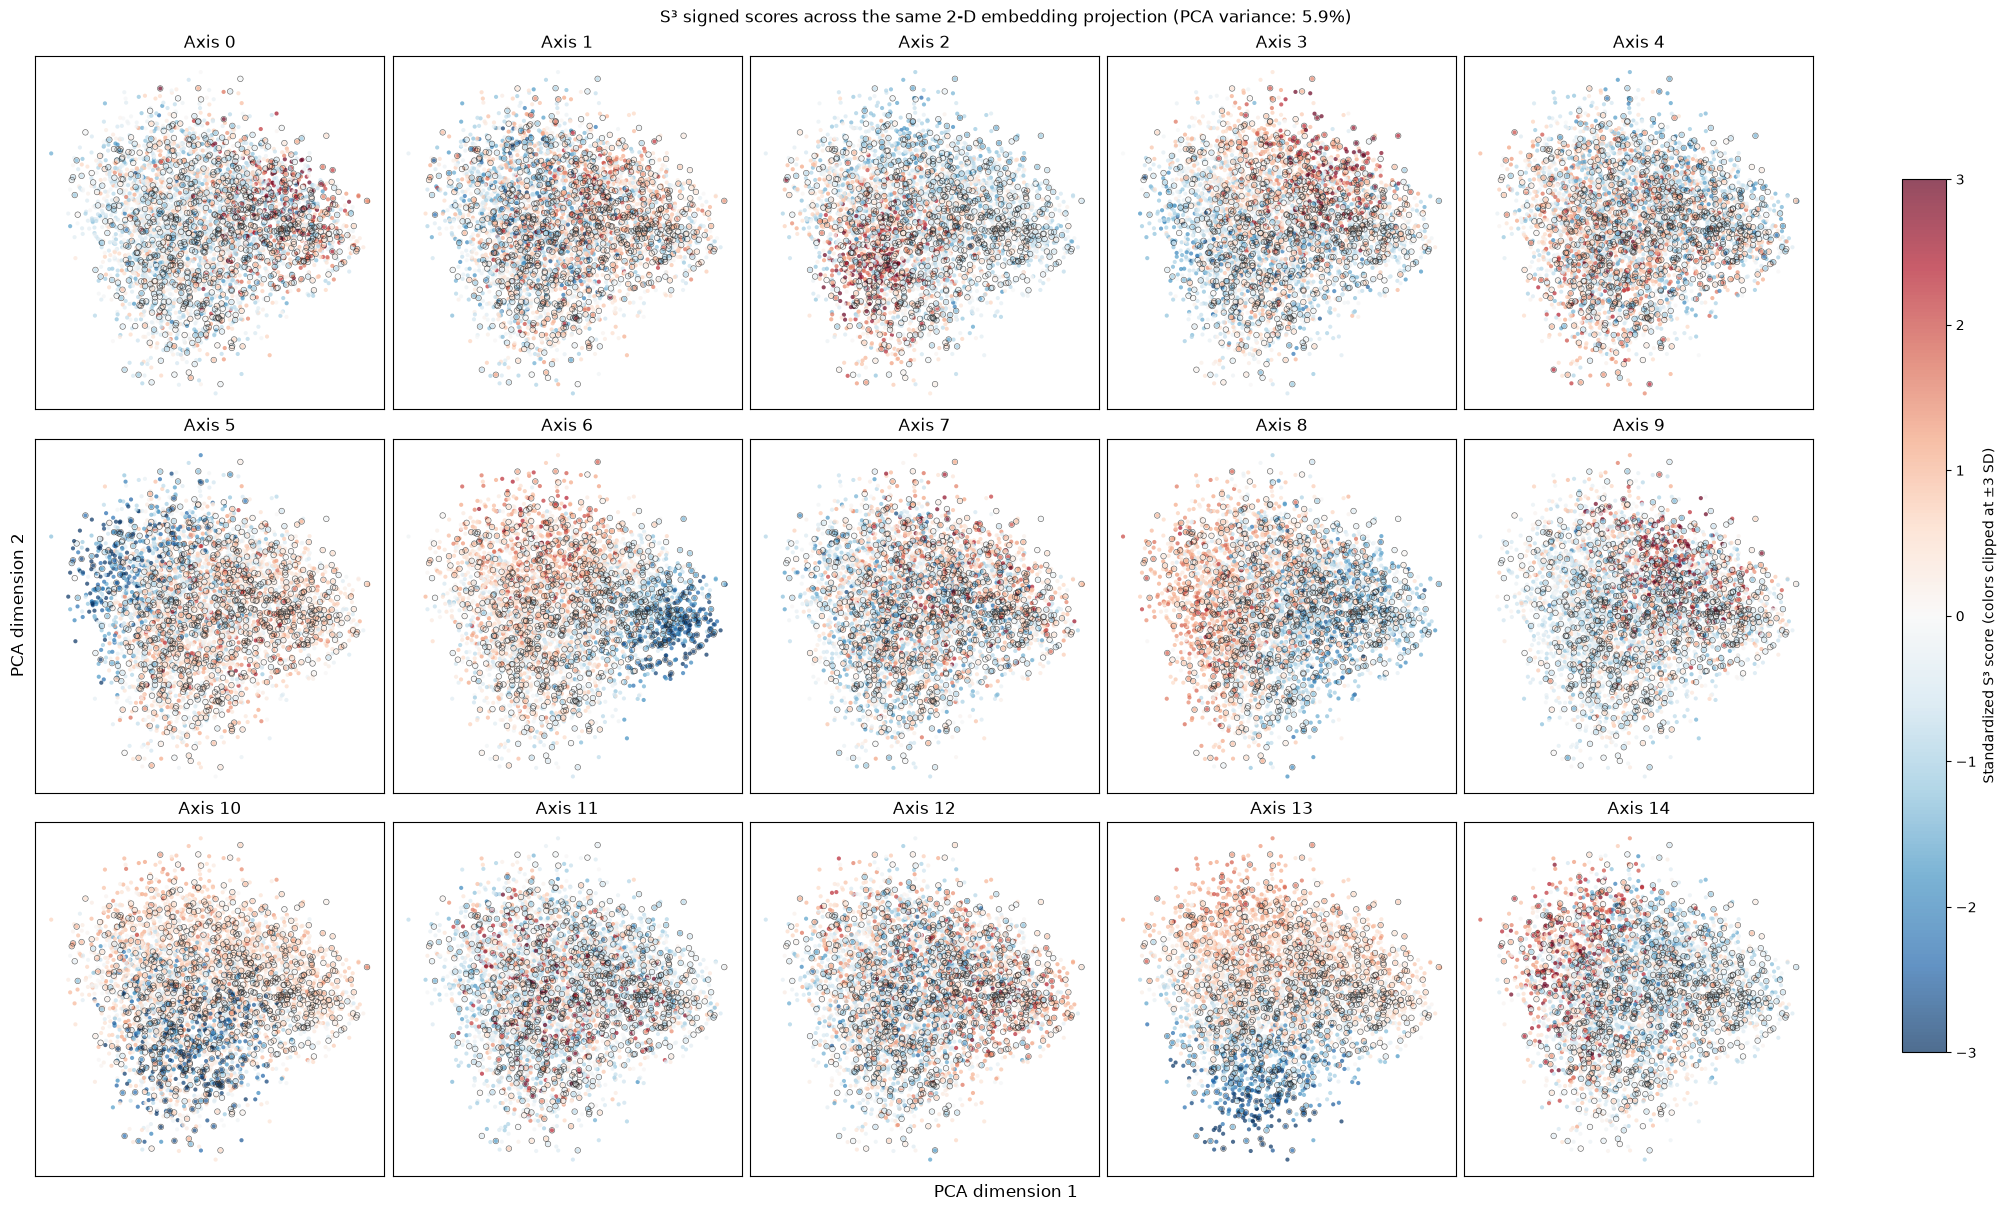

2-D projection uses the saved 1024-D vectors for 4,132 passages; BERTopic outliers outlined: 827.
Strongest passage at each end of each component; use both poles and review the linked transcript/audio before naming an axis.


,axis,positive terms,positive passage,negative terms,negative passage
0,0,"mitu, muidu, seesama, teed, tööd, juures, muud...",2267420990 | Püsimetsandus – kas kesktee metsa...,"rääkida, räägime, rääkima, ette, vot, ütleks, ...","2396670933 | Kui pole mugav, siis ei kaasa_! |..."
1,1,"arutelu, räägime, mõelda, parem, ütleb, mõtlem...",2250797873 | Vasakpoolsus Eestis. Kas turumõtl...,"teen, koolis, läks, jooksul, kooli, kuhu, kinn...",2396692743 | Järgmise põlvkonna õpilasmalev | ...
2,2,"tööle, töö, tööd, inimese, head, inimene, inim...",2247188693 | Töökius otse laval | 2700.8–3091....,"teen, riigi, huvi, arvan, sinu, kuhu, kindlast...","2400184980 | Eesti, Singapur, Dubai, Delaware...."
3,3,"jääb, korraks, aastat, minema, kuhu, tulevad, ...",2396670927 | Kodude kättesaadavus_ kas Eestil ...,"mulle, mul, selgelt, selles, noh, maailmas, ol...",2393585475 | Kas internet vajab korrakaitsjat_...
4,4,"erinevad, erinevaid, olid, mingisugune, mõned,...",2277338243 | Maailmahariduslik mälumäng ja mõt...,"riik, eesti, noor, ees, kes, eestis, eriti, töö",2247188684 | Kas kiirustades elad kauem? | 450...
5,5,"ikkagi, mõte, mul, tuhat, tundub, taha, ütles,...","2318409179 | Kas noortelt nõutakse rohkem, kui...","kodus, laps, lapsed, lapse, väike, hoida, last...",2300040491 | Lastekaitsetöö nähtamatu vastutus...
6,6,"inimeste, inimese, riigi, inimene, inimesed, i...",2300040503 | Annetuskultuur. Kuidas Eestist sa...,"hetkel, hakkab, tahan, võime, olete, pole, saa...",2387966370 | Kuidas edasi_ Eesti energeetika j...
7,7,"protsenti, kakskümmend, kolmkümmend, aastat, v...",2293106222 | Süstime rahva saledaks_ | 374.8–5...,"teha, küsida, leida, kõigile, samamoodi, juure...",2258666741 | Me paneme selle muuseumi kinni! |...
8,8,"rääkida, mõtlema, mõttes, rääkima, räägime, en...","2395857141 | Kes ütleb meile, et nemad pole me...","raha, tööle, tööd, riigi, töö, palju, käib, lahti",2400207741 | Kuidas rahastada terviseidusid ni...
9,9,"riigi, euroopa, riik, olukord, vastu, oska, os...",2271676346 | Ajateenistuse tulevikuvaade – kuh...,"selle, tee, teed, mõttes, mõtlema, tea, endale...",2397829638 | Kus on noore kodu_ Kuidas elataks...


In [5]:
projection = PCA(n_components=2, svd_solver='randomized', random_state=RANDOM_STATE).fit_transform(embeddings)
assert projection.shape == (len(passages), 2) and np.isfinite(projection).all()
projection_variance = PCA(n_components=2, svd_solver='randomized', random_state=RANDOM_STATE).fit(embeddings).explained_variance_ratio_.sum()
outlier_mask = passages.topic_id.eq(-1).to_numpy()
ncols = min(5, N_COMPONENTS)
nrows = (N_COMPONENTS + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), sharex=True, sharey=True, constrained_layout=True)
axes = np.asarray(axes).reshape(-1)
for component_id, ax in enumerate(axes):
    if component_id >= N_COMPONENTS:
        ax.set_visible(False)
        continue
    values = score_z.iloc[:, component_id].to_numpy()
    ax.scatter(projection[:, 0], projection[:, 1], c=values, cmap='RdBu_r', vmin=-3, vmax=3, s=9, alpha=0.7, linewidths=0, rasterized=True)
    ax.scatter(projection[outlier_mask, 0], projection[outlier_mask, 1], facecolors='none', edgecolors='#222222', s=16, linewidths=0.45, alpha=0.7, rasterized=True)
    ax.set_title(f'Axis {component_id}')
    ax.set_xticks([]); ax.set_yticks([])
fig.supxlabel('PCA dimension 1'); fig.supylabel('PCA dimension 2')
fig.suptitle(f'S³ signed scores across the same 2-D embedding projection (PCA variance: {projection_variance:.1%})')
fig.colorbar(axes.flat[0].collections[0], ax=axes.ravel().tolist(), label='Standardized S³ score (colors clipped at ±3 SD)', shrink=0.78)
plt.show()

assert len(score_z.columns) == N_COMPONENTS
assert len(projection) == len(passages) == len(scored_passages)
assert int(outlier_mask.sum()) == int((passages.topic_id == -1).sum())
print(f'2-D projection uses the saved {embeddings.shape[1]}-D vectors for {len(passages):,} passages; BERTopic outliers outlined: {outlier_mask.sum():,}.')

table_rows = []
for component_id, score_column in enumerate(score_columns):
    positive = scored_passages[score_column].idxmax()
    negative = scored_passages[score_column].idxmin()
    pos = scored_passages.loc[positive]
    neg = scored_passages.loc[negative]
    table_rows.append({
        'axis': component_id,
        'positive terms': ', '.join(positive_terms[component_id][:8]),
        'positive passage': f"{pos.get('episode_id', '')} | {pos.get('title', '')} | {pos.get('start_seconds', '')}–{pos.get('end_seconds', '')}s | BERTopic {pos.get('topic_id', '')} | score {pos[score_column]:.3f} | {pos.get('text', '')}",
        'negative terms': ', '.join(negative_terms[component_id][:8]),
        'negative passage': f"{neg.get('episode_id', '')} | {neg.get('title', '')} | {neg.get('start_seconds', '')}–{neg.get('end_seconds', '')}s | BERTopic {neg.get('topic_id', '')} | score {neg[score_column]:.3f} | {neg.get('text', '')}",
    })
axis_evidence_table = pd.DataFrame(table_rows)
assert len(axis_evidence_table) == N_COMPONENTS
print('Strongest passage at each end of each component; use both poles and review the linked transcript/audio before naming an axis.')
display(axis_evidence_table)

## Existing BERTopic groups across S³ axes

Each passage keeps its original BERTopic `topic_id` and membership strength. The heatmap summarizes mean standardized S³ scores for every topic × axis; the box plot lets you inspect the passage-score distribution for one axis at a time. Topic `-1` is retained. These are group associations, not recalculated BERTopic probabilities or a correlation with numeric topic IDs.

Raw per-passage S³ scores and topic-by-axis quantiles are saved as separate Parquet outputs; original assignments are not changed.

In [6]:
from pathlib import Path
import plotly.graph_objects as go
import sys
sys.path.insert(0, str(project_root))
from scripts.s3_topic_axis import summarize_topic_axis_scores

topic_axis_summary = summarize_topic_axis_scores(passages, score_frame)
assert topic_axis_summary.axis_id.nunique() == N_COMPONENTS
assert topic_axis_summary.passage_count.sum() == len(passages) * N_COMPONENTS
assert (topic_axis_summary.topic_id == -1).any(), 'BERTopic outlier group -1 should be retained'
assert np.array_equal(scored_passages.topic_id.to_numpy(), passages.topic_id.to_numpy())
if 'membership_strength' in passages:
    assert np.allclose(scored_passages.membership_strength.to_numpy(dtype=float), passages.membership_strength.to_numpy(dtype=float), equal_nan=True)

score_output_dir = results / 'jev-semantic-all' / 's3-topic-axis-distributions'
score_output_dir.mkdir(parents=True, exist_ok=True)
run_tag = f'k{N_COMPONENTS}-seed{RANDOM_STATE}'
passage_score_path = score_output_dir / f'passage-scores-{run_tag}.parquet'
topic_axis_summary_path = score_output_dir / f'topic-axis-summary-{run_tag}.parquet'
export_columns = [column for column in ['passage_id', 'episode_id', 'title', 'start_seconds', 'end_seconds', 'text', 'audio_url', 'topic_id', 'membership_strength'] if column in scored_passages] + score_columns
scored_passages[export_columns].to_parquet(passage_score_path, index=False)
topic_axis_summary.to_parquet(topic_axis_summary_path, index=False)

topic_order = sorted(topic_axis_summary.topic_id.unique().tolist())
topic_means = topic_axis_summary.pivot(index='topic_id', columns='axis_id', values='mean_score').reindex(index=topic_order, columns=range(N_COMPONENTS))
topic_counts = topic_axis_summary.pivot(index='topic_id', columns='axis_id', values='passage_count').reindex(index=topic_order, columns=range(N_COMPONENTS))
axis_means = score_frame.mean().to_numpy()
axis_stds = score_frame.std(ddof=0).replace(0, 1).to_numpy()
topic_mean_z = (topic_means.to_numpy() - axis_means) / axis_stds
heat_custom = np.stack([topic_counts.to_numpy(), topic_means.to_numpy()], axis=-1)
heat = go.Figure(go.Heatmap(z=topic_mean_z, x=[f'Axis {i}' for i in range(N_COMPONENTS)], y=[str(topic) for topic in topic_order], customdata=heat_custom, colorscale='RdBu_r', zmid=0, zmin=-2, zmax=2, colorbar={'title': 'Mean S³ z-score'}, hovertemplate='BERTopic topic %{y}<br>%{x}<br>mean score z=%{z:.2f}<br>passages=%{customdata[0]:.0f}<extra></extra>'))
heat.update_layout(title=f'Mean S³ score by original BERTopic topic (k={N_COMPONENTS})', xaxis_title='S³ axis', yaxis_title='Original BERTopic topic ID', height=max(700, min(1400, 9 * len(topic_order))), margin={'l': 90, 'r': 30, 't': 70, 'b': 70})
heat.show()

topic_labels = [str(topic) for topic in topic_order]
distribution = go.Figure()
for axis_id, score_column in enumerate(score_columns):
    distribution.add_trace(go.Box(x=scored_passages.topic_id.astype(str), y=score_z[score_column], name=f'Axis {axis_id}', boxpoints=False, visible=(axis_id == 0), hovertemplate='BERTopic topic %{x}<br>standardized S³ score=%{y:.2f}<extra></extra>'))
axis_buttons = [dict(label=f'Axis {axis_id}', method='update', args=[{'visible': [candidate == axis_id for candidate in range(N_COMPONENTS)]}, {'title': f'S³ score distribution by BERTopic topic — axis {axis_id}'}]) for axis_id in range(N_COMPONENTS)]
distribution.update_layout(title='S³ score distribution by BERTopic topic — axis 0', xaxis={'title': 'Original BERTopic topic ID', 'categoryorder': 'array', 'categoryarray': topic_labels, 'tickangle': -60}, yaxis_title='Standardized S³ score (not a probability)', updatemenus=[{'buttons': axis_buttons, 'direction': 'down', 'x': 1.0, 'xanchor': 'right', 'y': 1.16, 'yanchor': 'top'}], height=720, margin={'b': 150, 't': 100})
distribution.show()

print(f'Passage scores: {len(scored_passages):,} rows × {N_COMPONENTS} axes; BERTopic outliers retained: {(passages.topic_id == -1).sum():,}.')
print(f'Wrote {passage_score_path} and {topic_axis_summary_path}')
display(topic_axis_summary.sort_values('passage_count', ascending=False).head(12).reset_index(drop=True))

Passage scores: 4,132 rows × 15 axes; BERTopic outliers retained: 827.
Wrote C:\Users\risto\projects\arvamusfestivali_salvestused\data\topic-analysis\results\jev-semantic-all\s3-topic-axis-distributions\passage-scores-k15-seed42.parquet and C:\Users\risto\projects\arvamusfestivali_salvestused\data\topic-analysis\results\jev-semantic-all\s3-topic-axis-distributions\topic-axis-summary-k15-seed42.parquet


,topic_id,axis_id,passage_count,mean_score,std_score,median_score,q10_score,q25_score,q75_score,q90_score
0,-1,10,827,-0.053269,1.128725,0.254647,-2.006338,-0.312582,0.655266,0.966967
1,-1,2,827,-0.134085,0.821345,-0.203641,-1.119431,-0.660246,0.314860,0.839538
2,-1,5,827,0.191963,0.911310,0.279040,-0.901109,-0.200267,0.764672,1.153009
3,-1,4,827,0.105581,1.028215,0.175232,-1.260917,-0.665441,0.865065,1.391386
4,-1,14,827,0.041669,0.963700,-0.074067,-1.028733,-0.580142,0.468358,1.318691
5,-1,3,827,0.106892,0.973365,0.042043,-1.046415,-0.524746,0.647469,1.319260
6,-1,12,827,0.014425,0.951859,-0.019998,-1.190620,-0.626705,0.631487,1.266502
7,-1,8,827,0.103286,0.952890,0.138649,-1.217528,-0.556660,0.832489,1.285866
8,-1,11,827,-0.006418,1.086243,-0.200298,-1.074442,-0.714144,0.389962,1.198187
9,-1,9,827,-0.038765,0.924583,-0.155749,-1.033011,-0.650171,0.368365,1.053815


In [7]:
evidence_columns = [c for c in ['passage_id', 'episode_id', 'title', 'start_seconds', 'end_seconds', 'text', 'audio_url', 'topic_id', 'membership_strength'] if c in scored_passages.columns]
for i, score_column in enumerate(score_columns):
    print(f'Component {i}: highest-scoring passages')
    display(scored_passages.nlargest(3, score_column)[evidence_columns + [score_column]].reset_index(drop=True))
    print(f'Component {i}: lowest-scoring passages')
    display(scored_passages.nsmallest(3, score_column)[evidence_columns + [score_column]].reset_index(drop=True))
outliers = scored_passages.loc[scored_passages.topic_id == -1].copy()
outlier_view = outliers[evidence_columns + score_columns].sort_values(score_columns[0], key=lambda x: x.abs(), ascending=False)
print(f'Outliers shown for additional evidence review: {len(outliers):,} total; first 12 by absolute component-0 score.')
display(outlier_view.head(12).reset_index(drop=True))

Component 0: highest-scoring passages


,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_0
0,2267420990:000001807840-000001937680,2267420990,Püsimetsandus – kas kesktee metsakaitse ja met...,1807.84,1937.68,on üks osa sellest püsiva metsakattega majanda...,55,1.0,4.687684
1,2267420987:000001404840-000001921000,2267420987,Kliimatark metsandus. Kuidas kohaneda ja tegut...,1404.84,1921.00,on seost selle kliima targa metsanduse eesmärk...,221,1.0,4.686991
2,2267420990:000000635080-000001026000,2267420990,Püsimetsandus – kas kesktee metsakaitse ja met...,635.08,1026.00,"tean oma kogemusest, et, et nii nagu lageraiet...",55,1.0,4.599414


Component 0: lowest-scoring passages


,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_0
0,2396670933:000004513760-000004825978,2396670933,"Kui pole mugav, siis ei kaasa_!",4513.76,4825.978,Tuleb midagi praktilist ka siit paneelist nagu...,135,1.000000,-2.736689
1,2314163831:000005039720-000005424091,2314163831,Kuidas reisides mitte lolliks jääda_,5039.72,5424.091,"he, selline šokk. Et ja ikka mõned kohad on. N...",27,0.627636,-2.603693
2,2258666744:000003827240-000004150857,2258666744,Rahvus: inimene,3827.24,4150.857,Selle protsesside puhul ja kui nad peavad ka e...,74,0.806938,-2.565794


Component 1: highest-scoring passages


...

,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_14
0,2289585032:000001271080-000001758800,2289585032,Tehisaru koolipingis. Kas õpetaja parim abilin...,1271.08,1758.80,"Pärast arutelu saab artikleid tasuta, võib-oll...",139,1.000000,3.563527
1,2289585032:000003310680-000003502320,2289585032,Tehisaru koolipingis. Kas õpetaja parim abilin...,3310.68,3502.32,lüüa oma õpivõimel. Mismoodi õppe hindamine võ...,7,0.683835,3.519771
2,2310594920:000004912400-000005035520,2310594920,Mul jäi isegi Tiigrihüpe tegemata.alp,4912.40,5035.52,ka õpetada. Aitäh. Ma korra kasutan vägivaldse...,-1,NaN,3.415413


Component 14: lowest-scoring passages


,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_14
0,2314163831:000002787760-000003174160,2314163831,Kuidas reisides mitte lolliks jääda_,2787.76,3174.16,"elavad sildid, siis noh, me saame aru, et see ...",27,0.465761,-2.727252
1,2267420993:000001581320-000001721080,2267420993,"Mõõdame eurodes, mitte tihumeetrites",1581.32,1721.08,"Fredi, sina küpsetad puitu kaugetele eksootili...",-1,NaN,-2.621173
2,2396670936:000000423560-000000658840,2396670936,"Kas Eesti on valmis järgmiseks kriisiks, mis e...",423.56,658.84,"You know, you don't relate to it. It is not so...",96,0.029868,-2.565989


Outliers shown for additional evidence review: 827 total; first 12 by absolute component-0 score.


,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_0,s3_component_1,...,s3_component_5,s3_component_6,s3_component_7,s3_component_8,s3_component_9,s3_component_10,s3_component_11,s3_component_12,s3_component_13,s3_component_14
0,2267420987:000004712040-000005005000,2267420987,Kliimatark metsandus. Kuidas kohaneda ja tegut...,4712.04,5005.00,"Seda ma kindlasti mitte ei väida, sest nagu öe...",-1,NaN,4.572917,0.705660,...,0.330447,-0.506568,0.296180,0.514358,0.337647,0.183874,-0.478949,0.708345,0.388410,-0.098265
1,2267420996:000001113080-000001531280,2267420996,"Eesti inimesed soovivad, ökoloogid soovitavad ...",1113.08,1531.28,"Siis keskkonnaagentuur on teinud, praegu raiut...",-1,NaN,4.250131,-0.275569,...,0.339772,0.136815,0.578402,0.261459,-0.012273,-0.064712,0.159338,-0.791252,-1.053713,0.190189
2,2267420987:000002566480-000002700000,2267420987,Kliimatark metsandus. Kuidas kohaneda ja tegut...,2566.48,2700.00,"siis oleks parem puit, suurem lülipuidu sisald...",-1,NaN,4.112985,0.166201,...,0.601365,-0.575225,-0.602822,0.292032,-0.590371,-0.184664,-0.215045,0.999388,0.408314,0.537617
3,2267420990:000005300520-000005408280,2267420990,Püsimetsandus – kas kesktee metsakaitse ja met...,5300.52,5408.28,"On ju öeldud juba pikka aega, et väikemetsaoma...",-1,NaN,3.778321,0.050069,...,-0.386261,0.610895,-1.718739,-0.607587,0.440238,0.779490,-0.097634,-1.076112,-0.201424,-0.684340
4,2267420987:000004231200-000004582280,2267420987,Kliimatark metsandus. Kuidas kohaneda ja tegut...,4231.20,4582.28,"ldab seda, mida rohkem me suudame industrialis...",-1,NaN,3.639012,0.180044,...,0.124187,-0.312604,1.227705,-0.843545,0.324192,0.532050,0.300825,-0.572676,0.315125,0.118057
5,2267420987:000000238120-000000819920,2267420987,Kliimatark metsandus. Kuidas kohaneda ja tegut...,238.12,819.92,kasvatuse kaasprofessor. Et publikut ikkagi ka...,-1,NaN,3.619265,0.602128,...,0.083711,-0.890361,0.311305,1.101442,-0.846288,0.560934,1.203620,0.656729,0.023676,-0.028573
6,2267420987:000005136120-000005366400,2267420987,Kliimatark metsandus. Kuidas kohaneda ja tegut...,5136.12,5366.40,"tsa, mis meil hetkel on, mida on nii-öelda või...",-1,NaN,3.589915,-0.092222,...,0.675350,-0.896639,0.166202,0.255021,-0.442946,0.464495,-0.798467,-1.020761,0.126766,-0.247511
7,2267420987:000002371280-000002566480,2267420987,Kliimatark metsandus. Kuidas kohaneda ja tegut...,2371.28,2566.48,võib-olla järjest rohkem mõeldakse selle peale...,-1,NaN,3.573245,0.360295,...,-0.145103,0.244348,0.151722,-0.257506,-0.144383,1.115440,-1.436986,-1.281794,-0.153867,-0.411159
8,2267420999:000001004800-000001262800,2267420999,Kas tulevikumetsad vajavad rangemat kaitset võ...,1004.80,1262.80,ja noh. Tegelikult sul on ka natuke nagu teist...,-1,NaN,3.565547,-1.957061,...,-0.328750,-0.022502,-0.471983,0.100089,-0.352564,0.604569,-0.557907,-1.714709,0.376125,-1.726744
9,2254333412:000003165360-000003364120,2254333412,Millist väliruumi ootame oma linnadesse_ LIFE ...,3165.36,3364.12,"le püüda, jättes tähelepanuta, et nendesamade ...",-1,NaN,3.422221,-0.947467,...,0.161662,0.905084,-0.931069,-0.309558,-0.530218,0.659863,0.167000,0.260501,0.024276,-0.357509
